# 11 Domain Shift

Data latih dan data target berasal dari domain berbeda. Contoh: latih dari ulasan dan berita (SmSA),
target komentar YouTube tentang MBG.

**Peringatan data:** label target di sini **hasil keluaran model lain**, bukan anotasi manusia, dan
hanya dipakai untuk audit. Skor audit perlu dibaca sebagai petunjuk arah, bukan kebenaran.

**Daftar isi**

1. Kartu Masalah
2. Kapan Pakai Notebook Ini
3. Config
4. EDA
5. Preprocessing
6. Validasi
7. Baseline
8. Model Utama
9. Post-processing
10. Post-analysis
11. Keluaran

## 1. Kartu Masalah

ISI_SETELAH_EDA

## 2. Kapan Pakai Notebook Ini

**Pakai kalau** AUC adversarial antara train dan test tinggi, misalnya di atas 0,7, atau soal memang
menyebut sumber data berbeda. Tanda khasnya skor validasi bagus tapi skor leaderboard jatuh.

**Yang perlu diganti kalau datanya beda:**
- `load_source` dan `load_target`.
- `ALLOW_TARGET_TRAINING`, cek dulu apakah aturan lomba membolehkan data test dipakai saat training.
- Sel audit di bagian 10 dihapus kalau label target tidak ada.

## 3. Config

**Import dan lingkungan.** Mode offline dinyalakan di sini, dan progress bar serta warning
dimatikan supaya output tetap bersih.

In [1]:
import importlib.util
import json
import os
import random
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from pathlib import Path

os.environ.update(
    CUDA_VISIBLE_DEVICES="0",
    HF_HUB_OFFLINE="1",
    TRANSFORMERS_OFFLINE="1",
    TOKENIZERS_PARALLELISM="false",
    TQDM_DISABLE="1",
    PYTHONWARNINGS="ignore",
    HF_HUB_DISABLE_PROGRESS_BARS="1",
)
warnings.filterwarnings("ignore")
sys.modules["tensorflow"] = None  # tidak dipakai; mencegah log TensorFlow saat umap diimpor

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90, "display.max_rows", 30, "display.width", 140)
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.5),
        "figure.dpi": 90,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print(f"device={DEVICE} | torch={torch.__version__}")

device=cuda | torch=2.11.0+cu130


**Lokasi file.** `find_pack` mencari paket offline, dan `find_file` mencari file data di Kaggle
atau folder lokal. Di mesin lokal, set `PACK_DIR` dan `DATA_ROOT` lewat environment variable.

In [2]:
INPUT_ROOTS = [Path(p) for p in (os.environ.get("DATA_ROOT"), "/kaggle/input", ".") if p]


def find_pack() -> Path:
    """Cari folder paket offline lewat file pack_manifest.json."""
    if os.environ.get("PACK_DIR"):
        return Path(os.environ["PACK_DIR"])
    for root in INPUT_ROOTS:
        for manifest in root.glob("**/pack_manifest.json"):
            return manifest.parent
    raise FileNotFoundError("Paket offline tidak ketemu. Set environment variable PACK_DIR.")


def find_file(name: str) -> Path:
    """Cari file data berdasarkan nama di semua folder input."""
    for root in INPUT_ROOTS:
        for path in root.glob(f"**/{name}"):
            return path
    raise FileNotFoundError(f"File {name} tidak ketemu di {INPUT_ROOTS}")


def install_offline(*modules: str) -> None:
    """Pasang library dari wheel paket offline, hanya bila belum terpasang."""
    missing = [m for m in modules if importlib.util.find_spec(m.replace("-", "_")) is None]
    if missing:
        subprocess.run(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "--no-index",
                "--find-links",
                str(PACK_DIR / "wheels"),
                "--root-user-action=ignore",
                *missing,
            ],
            check=True,
        )


PACK_DIR = find_pack()
MODEL_DIR = PACK_DIR / "models"
EXTRA_DATA_DIR = PACK_DIR / "data"
RESULT_DIR = Path("hasil")
RESULT_DIR.mkdir(exist_ok=True)
print(f"paket offline: {PACK_DIR}")

paket offline: /kaggle/input/notebooks/ivanwllm/gemastik-nlp-00-setup-offline


**Pencatat waktu dan ringkasan.** `stage` mencatat durasi tiap tahap, dan `run_summary` mencetak
ringkasan akhir yang dibaca skrip audit.

In [3]:
RUN_START = time.time()
STAGE_SECONDS: dict[str, float] = {}


@contextmanager
def stage(name: str):
    """Catat durasi satu tahap."""
    start = time.time()
    yield
    STAGE_SECONDS[name] = round(time.time() - start, 1)
    print(f"[waktu] {name}: {STAGE_SECONDS[name]:.0f} detik")


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def run_summary(task: str, n_rows: int, metrics: dict, needs_gpu: bool = True) -> None:
    """Simpan dan cetak ringkasan run."""
    total = int(time.time() - RUN_START)
    used_gpu = torch.cuda.is_available() and torch.cuda.max_memory_allocated() > 0
    summary = {
        "task": task,
        "mode": MODE,
        "use_pretrained": USE_PRETRAINED,
        "n_rows": n_rows,
        "total_detik": total,
        "gpu": used_gpu,
        "tahap_detik": STAGE_SECONDS,
        "metrik": metrics,
    }
    (RESULT_DIR / "ringkasan.json").write_text(json.dumps(summary, indent=1))
    note = "" if needs_gpu else " gpu_tidak_wajib"
    print(
        f"RINGKASAN_RUN task={task} mode={MODE} n_rows={n_rows} total_detik={total} "
        f"gpu={used_gpu}{note}"
    )
    print(json.dumps(metrics, indent=1))

**Pengaturan utama.** Semua yang perlu diubah ada di sel ini.

In [4]:
MODE = "penuh"  # "cepat" (<30 menit) atau "penuh" (<2 jam)
USE_PRETRAINED = True  # False: hanya TF-IDF, tanpa file model dari luar
ALLOW_TARGET_TRAINING = True  # hanya kalau aturan lomba membolehkan
SEED = 42
N_ROWS = 5000
GUARDRAIL_SHARE = 0.15
AUDIT_MIN_CONFIDENCE = 0.8
CLASSES = ["negative", "neutral", "positive"]
PSEUDO_TOP_FRACTION = 0.4
PSEUDO_MIN_CONFIDENCE = 0.7
MIN_GUARD_GAIN = 0.002  # student dipakai hanya kalau skor penjaga naik minimal sebesar ini

SETTINGS = {
    "cepat": {
        "epochs": 2,
        "student_epochs": 2,
        "rounds": 1,
        "model_runs": [("indobertweet", SEED)],
    },
    "penuh": {
        "epochs": 3,
        "student_epochs": 2,
        "rounds": 2,
        "model_runs": [("indobertweet", SEED), ("indobert", SEED), ("indobertweet", SEED + 1)],
    },
}[MODE]

seed_everything(SEED)
print(SETTINGS)

{'epochs': 3, 'student_epochs': 2, 'rounds': 2, 'model_runs': [('indobertweet', 42), ('indobert', 42), ('indobertweet', 43)]}


**Util teks.** `clean_text` hanya membuang gangguan teknis (URL, mention, spasi) dan
mempertahankan emoji serta tanda seru karena keduanya membawa sinyal. `normalize_slang` memakai
kamus alay. `near_duplicate_groups` menemukan komentar kembar supaya tidak bocor antar fold.

In [5]:
import re  # noqa: E402

from sklearn.feature_extraction.text import TfidfVectorizer  # noqa: E402
from sklearn.linear_model import LogisticRegression  # noqa: E402
from sklearn.metrics import roc_auc_score  # noqa: E402
from sklearn.model_selection import cross_val_predict  # noqa: E402
from sklearn.neighbors import NearestNeighbors  # noqa: E402

URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
SPACE_RE = re.compile(r"\s+")


def clean_text(text: str) -> str:
    """Bersihkan URL, mention, dan spasi berlebih. Huruf kecil, emoji tetap."""
    text = URL_RE.sub(" ", str(text))
    text = MENTION_RE.sub(" ", text)
    return SPACE_RE.sub(" ", text).strip().lower()


def load_slang_dict() -> dict[str, str]:
    """Muat kamus kata informal ke kata baku."""
    path = next((EXTRA_DATA_DIR / "kamus_alay").glob("**/colloquial-indonesian-lexicon.csv"))
    lexicon = pd.read_csv(path)
    return dict(zip(lexicon["slang"].astype(str), lexicon["formal"].astype(str)))


def normalize_slang(text: str, slang: dict[str, str]) -> str:
    """Ganti kata informal dengan kata baku, per kata."""
    return " ".join(slang.get(word, word) for word in text.split())


def near_duplicate_groups(texts: list[str], threshold: float = 0.9) -> np.ndarray:
    """Beri id grup yang sama pada teks yang kemiripan char TF-IDF-nya di atas threshold."""
    vectors = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1).fit_transform(texts)
    neighbors = NearestNeighbors(n_neighbors=min(6, len(texts)), metric="cosine").fit(vectors)
    distance, index = neighbors.kneighbors(vectors)
    parent = list(range(len(texts)))

    def root(i: int) -> int:
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, (row_dist, row_idx) in enumerate(zip(distance, index)):
        for dist, j in zip(row_dist, row_idx):
            if dist <= 1 - threshold:
                parent[root(i)] = root(int(j))
    return np.array([root(i) for i in range(len(texts))])


def adversarial_auc(texts_a: list[str], texts_b: list[str]) -> float:
    """AUC model yang membedakan dua kumpulan teks. Dekat 0,5 berarti tidak ada shift."""
    texts = list(texts_a) + list(texts_b)
    target = np.array([0] * len(texts_a) + [1] * len(texts_b))
    vectors = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    scores = cross_val_predict(model, vectors, target, cv=3, method="predict_proba")[:, 1]
    return float(roc_auc_score(target, scores))


def text_profile(texts: pd.Series) -> pd.Series:
    """Ringkasan kualitas teks untuk EDA."""
    words = texts.astype(str).str.split().str.len()
    return pd.Series(
        {
            "baris": len(texts),
            "kosong": int((words == 0).sum()),
            "duplikat_persis_%": round(100 * texts.duplicated().mean(), 1),
            "kata_median": float(words.median()),
            "kata_p95": float(words.quantile(0.95)),
            "kata_maks": int(words.max()),
            "ada_url_%": round(100 * texts.astype(str).str.contains(r"https?://").mean(), 1),
            "ada_emoji_%": round(
                100 * texts.astype(str).str.contains(r"[\U0001F300-\U0001FAFF]").mean(), 1
            ),
        }
    )

**Training transformer.** Satu fungsi untuk klasifikasi (`problem="ce"`), multi-label (`"bce"`),
dan regresi (`"mse"`). Loop-nya ditulis sendiri supaya mudah dibaca dan outputnya bersih.

In [6]:
from torch.utils.data import DataLoader, TensorDataset  # noqa: E402
from transformers import (  # noqa: E402
    AutoModelForSequenceClassification,
    AutoTokenizer as _SeqTokenizer,
    get_linear_schedule_with_warmup,
)


def _encode(tokenizer, texts, pairs, max_len):
    args = (list(texts), list(pairs)) if pairs is not None else (list(texts),)
    tokens = tokenizer(
        *args, padding="max_length", truncation=True, max_length=max_len, return_tensors="pt"
    )
    return tokens["input_ids"], tokens["attention_mask"]


def _loss_fn(problem, weights):
    if problem == "ce":
        return torch.nn.CrossEntropyLoss(weight=weights)
    # untuk multi-label, class_weights berperan sebagai pos_weight per label
    return (
        torch.nn.BCEWithLogitsLoss(pos_weight=weights) if problem == "bce" else torch.nn.MSELoss()
    )


def _to_output(logits, problem):
    if problem == "ce":
        return torch.softmax(logits.float(), dim=1)
    if problem == "bce":
        return torch.sigmoid(logits.float())
    return logits.float().squeeze(-1)


@torch.inference_mode()
def _predict(model, ids, mask, problem, batch_size):
    model.eval()
    chunks = []
    for start in range(0, len(ids), batch_size):
        batch_ids = ids[start : start + batch_size].to(DEVICE)
        batch_mask = mask[start : start + batch_size].to(DEVICE)
        with torch.autocast("cuda", enabled=DEVICE == "cuda"):
            logits = model(input_ids=batch_ids, attention_mask=batch_mask).logits
        chunks.append(_to_output(logits, problem).cpu())
    return torch.cat(chunks).numpy()


def train_predict(
    model_name,
    train_texts,
    train_y,
    predict_sets,
    problem="ce",
    num_labels=None,
    class_weights=None,
    train_pairs=None,
    epochs=3,
    lr=2e-5,
    batch_size=32,
    max_len=128,
    seed=42,
):
    """Latih satu model, lalu kembalikan prediksi untuk tiap set di predict_sets.

    predict_sets: daftar teks, atau daftar pasangan (teks, teks_pair) untuk tugas dua teks.
    """
    seed_everything(seed)
    tokenizer = _SeqTokenizer.from_pretrained(MODEL_DIR / model_name)
    num_labels = num_labels or (int(np.max(train_y)) + 1 if problem == "ce" else 1)
    if problem == "bce":
        num_labels = np.asarray(train_y).shape[1]
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_DIR / model_name, num_labels=num_labels, ignore_mismatched_sizes=True
    ).to(DEVICE)

    ids, mask = _encode(tokenizer, train_texts, train_pairs, max_len)
    target = torch.tensor(np.asarray(train_y), dtype=torch.long if problem == "ce" else torch.float)
    if problem == "mse":
        target = target.view(-1, 1)
    loader = DataLoader(
        TensorDataset(ids, mask, target),
        batch_size=batch_size,
        shuffle=True,
        drop_last=len(ids) > batch_size,
    )
    weights = (
        None if class_weights is None else torch.tensor(class_weights, dtype=torch.float).to(DEVICE)
    )
    loss_fn = _loss_fn(problem, weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = max(1, epochs * len(loader))
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")

    model.train()
    for _ in range(epochs):
        for batch_ids, batch_mask, batch_y in loader:
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=DEVICE == "cuda"):
                logits = model(
                    input_ids=batch_ids.to(DEVICE), attention_mask=batch_mask.to(DEVICE)
                ).logits
                loss = loss_fn(logits, batch_y.to(DEVICE))
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

    outputs = []
    for item in predict_sets:
        texts, pairs = item if isinstance(item, tuple) else (item, None)
        pred_ids, pred_mask = _encode(tokenizer, texts, pairs, max_len)
        outputs.append(_predict(model, pred_ids, pred_mask, problem, batch_size * 2))
    del model, optimizer, scaler
    torch.cuda.empty_cache()
    return outputs

**Fungsi gambar confusion matrix**, dipakai di bagian post-analysis.

In [7]:
from sklearn.metrics import confusion_matrix  # noqa: E402


def plot_confusion(y_true, y_pred, names, title="Confusion matrix") -> None:
    matrix = confusion_matrix(y_true, y_pred, normalize="true")
    fig, ax = plt.subplots(figsize=(4.8, 3.8))
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    ticks = range(len(names))
    ax.set(
        xticks=ticks,
        yticks=ticks,
        xticklabels=names,
        yticklabels=names,
        title=title,
        xlabel="prediksi",
        ylabel="asli",
    )
    ax.grid(False)
    for (row, col), value in np.ndenumerate(matrix):
        ax.text(col, row, f"{value:.2f}", ha="center", va="center")
    fig.colorbar(image)
    plt.tight_layout()
    plt.show()

## 4. EDA

Muat sumber dan target. Label target disisihkan untuk audit.

In [8]:
from sklearn.metrics import f1_score  # noqa: E402
from sklearn.model_selection import train_test_split  # noqa: E402


def load_source() -> pd.DataFrame:
    path = EXTRA_DATA_DIR / "indonlu/dataset/smsa_doc-sentiment-prosa/train_preprocess.tsv"
    frame = pd.read_csv(path, sep="\t", header=None, names=["text", "label"])
    return frame.sample(n=N_ROWS, random_state=SEED).reset_index(drop=True)


def load_target() -> pd.DataFrame:
    frame = pd.read_csv(find_file("comment_sentiment.csv")).dropna(subset=["Cleaned Comment"])
    frame = frame.rename(
        columns={"Cleaned Comment": "text", "Sentiment": "label", "Confidence Score": "conf"}
    )
    return frame[["text", "label", "conf"]].head(N_ROWS).reset_index(drop=True)


source, target = load_source(), load_target()
target_labels, target_conf = target.pop("label"), target.pop("conf")
print(f"sumber={len(source)} | target={len(target)}")
pd.DataFrame({"sumber": text_profile(source["text"]), "target": text_profile(target["text"])})

sumber=5000 | target=5000


,sumber,target
baris,5000.0,5000.0
kosong,0.0,0.0
duplikat_persis_%,0.3,0.8
kata_median,28.0,17.0
kata_p95,71.0,89.0
kata_maks,110.0,1485.0
ada_url_%,0.0,0.0
ada_emoji_%,0.0,13.4


**Seberapa besar pergeserannya?** AUC adversarial dan kata yang paling membedakan kedua domain.

In [9]:
shift_auc = adversarial_auc(source["text"].tolist(), target["text"].tolist())
print(f"AUC adversarial sumber vs target: {shift_auc:.3f}")
vectorizer = TfidfVectorizer(min_df=5, token_pattern=r"\b[a-z]{3,}\b")
matrix = vectorizer.fit_transform(
    pd.concat([source["text"].str.lower(), target["text"].str.lower()])
)
domain = np.array([0] * len(source) + [1] * len(target))
coef = LogisticRegression(max_iter=1000).fit(matrix, domain).coef_[0]
vocab = np.array(vectorizer.get_feature_names_out())
print("khas sumber:", ", ".join(vocab[np.argsort(coef)[:12]]))
print("khas target:", ", ".join(vocab[np.argsort(-coef)[:12]]))

AUC adversarial sumber vs target: 0.992


khas sumber: nya, tidak, enak, tempat, demokrat, jokowi, bandung, dengan, yang, sini, pelayanan, fpi
khas target: mbg, prof, program, gema, korupsi, gak, sppg, data, aja, sekolah, pemerintah, quot


**Temuan dan keputusan**

ISI_SETELAH_EDA

## 5. Preprocessing

Pembersihan ringan dan **sama persis** di kedua domain. Slang tetap dipertahankan, karena IndoBERTweet
dilatih dari teks informal seperti target.

In [10]:
class_to_id = {name: i for i, name in enumerate(CLASSES)}
source["clean"] = source["text"].map(clean_text)
target["clean"] = target["text"].map(clean_text)
target_texts = target["clean"].tolist()
y_target = target_labels.map(class_to_id).to_numpy()
fit_rows, guard_rows = train_test_split(
    source, test_size=GUARDRAIL_SHARE, stratify=source["label"], random_state=SEED
)
fit_texts = fit_rows["clean"].tolist()
guard_texts = guard_rows["clean"].tolist()
y_fit = fit_rows["label"].map(class_to_id).to_numpy()
y_guard = guard_rows["label"].map(class_to_id).to_numpy()
print(f"latih={len(fit_texts)} | penjaga_sumber={len(guard_texts)} | target={len(target_texts)}")

latih=4250 | penjaga_sumber=750 | target=5000


## 6. Validasi

Dua alat ukur, dan keduanya bukan cross-validation biasa karena CV di sumber tidak mewakili target:
- **Skor penjaga di sumber:** memastikan adaptasi tidak merusak kemampuan dasar model.
- **Distribusi prediksi target:** harus masuk akal, tidak semua masuk satu kelas.
- **Skor audit target:** hanya untuk laporan. Di soal asli tidak ada.

In [11]:
def macro_f1(y_true, y_pred) -> float:
    return float(f1_score(y_true, y_pred, average="macro", zero_division=0))


assert abs(macro_f1([0, 0, 1, 1], [0, 1, 1, 1]) - (2 / 3 + 0.8) / 2) < 1e-9
sure = target_conf.to_numpy() >= AUDIT_MIN_CONFIDENCE
print(f"baris audit yakin: {sure.mean():.1%}")
results: list[dict] = []


def record(name: str, guard_probs: np.ndarray, target_probs: np.ndarray) -> None:
    pred = target_probs.argmax(1)
    share = np.bincount(pred, minlength=len(CLASSES)) / len(pred)
    results.append(
        {
            "model": name,
            "penjaga_sumber": round(macro_f1(y_guard, guard_probs.argmax(1)), 4),
            "audit_target": round(macro_f1(y_target, pred), 4),
            "audit_target_yakin": round(macro_f1(y_target[sure], pred[sure]), 4),
            "proporsi_target": dict(zip(CLASSES, share.round(2).tolist())),
        }
    )
    print(results[-1])

baris audit yakin: 78.5%


## 7. Baseline

TF-IDF dilatih hanya dari sumber. Skor audit di target menunjukkan seberapa parah dampak pergeseran.

In [12]:
word_tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
x_fit = word_tfidf.fit_transform(fit_texts)
tfidf_model = LogisticRegression(C=3.0, max_iter=2000, class_weight="balanced").fit(x_fit, y_fit)
guard_tfidf = tfidf_model.predict_proba(word_tfidf.transform(guard_texts))
target_tfidf = tfidf_model.predict_proba(word_tfidf.transform(target_texts))
record("tfidf_sumber_saja", guard_tfidf, target_tfidf)

{'model': 'tfidf_sumber_saja', 'penjaga_sumber': 0.816, 'audit_target': 0.5004, 'audit_target_yakin': 0.5189, 'proporsi_target': {'negative': 0.69, 'neutral': 0.2, 'positive': 0.11}}


## 8. Model Utama

**Self-training ke domain target.** Teacher dilatih dari sumber, lalu memberi pseudo-label pada target.
Student dilatih dari sumber + pseudo-label target, jadi mulai mengenal gaya bahasa target. Kuota per kelas
mengikuti proporsi prediksi teacher. Kuota seragam terbukti memaksa kelas langka menjadi terlalu banyak.

In [13]:
def fit_predict(model_name, texts, labels, epochs, seed):
    """Kembalikan probabilitas untuk penjaga dan target."""
    if not USE_PRETRAINED:
        vector = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
        model = LogisticRegression(C=3.0, max_iter=2000, class_weight="balanced")
        model.fit(vector.fit_transform(texts), labels)
        return [model.predict_proba(vector.transform(t)) for t in (guard_texts, target_texts)]
    weights = len(labels) / (len(CLASSES) * np.bincount(labels, minlength=len(CLASSES)))
    return train_predict(
        model_name,
        texts,
        labels,
        [guard_texts, target_texts],
        num_labels=len(CLASSES),
        class_weights=weights,
        epochs=epochs,
        seed=seed,
    )


def select_pseudo(probs: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Kuota mengikuti proporsi prediksi saat ini, karena proporsi asli target tidak diketahui."""
    pred, confidence = probs.argmax(1), probs.max(1)
    budget = PSEUDO_TOP_FRACTION * len(probs)
    shares = np.bincount(pred, minlength=probs.shape[1]) / len(probs)
    picked = []
    for cls in range(probs.shape[1]):
        members = np.where((pred == cls) & (confidence >= PSEUDO_MIN_CONFIDENCE))[0]
        picked.append(members[np.argsort(-confidence[members])][: int(budget * shares[cls])])
    index = np.concatenate(picked)
    return index, pred[index]


n_models = len(SETTINGS["model_runs"])
guard_teacher, target_teacher = np.zeros_like(guard_tfidf), np.zeros_like(target_tfidf)
guard_student, target_student = np.zeros_like(guard_tfidf), np.zeros_like(target_tfidf)
audit_rows = []
with stage("self_training"):
    for model_name, seed in SETTINGS["model_runs"]:
        g_t, t_t = fit_predict(model_name, fit_texts, y_fit, SETTINGS["epochs"], seed)
        guard_teacher += g_t / n_models
        target_teacher += t_t / n_models
        g_s, t_s = g_t, t_t
        if ALLOW_TARGET_TRAINING:
            for _ in range(SETTINGS["rounds"]):
                index, pseudo = select_pseudo(t_s)
                g_s, t_s = fit_predict(
                    model_name,
                    fit_texts + [target_texts[i] for i in index],
                    np.concatenate([y_fit, pseudo]),
                    SETTINGS["student_epochs"],
                    seed,
                )
            audit_rows.append(pd.DataFrame({"index": index, "pseudo": pseudo}))
        guard_student += g_s / n_models
        target_student += t_s / n_models
record("teacher_sumber_saja", guard_teacher, target_teacher)
record("student_self_training", guard_student, target_student)

[waktu] self_training: 852 detik
{'model': 'teacher_sumber_saja', 'penjaga_sumber': 0.9517, 'audit_target': 0.6799, 'audit_target_yakin': 0.7446, 'proporsi_target': {'negative': 0.64, 'neutral': 0.16, 'positive': 0.2}}
{'model': 'student_self_training', 'penjaga_sumber': 0.9502, 'audit_target': 0.6424, 'audit_target_yakin': 0.696, 'proporsi_target': {'negative': 0.56, 'neutral': 0.23, 'positive': 0.2}}


## 9. Post-processing

Student diterima hanya kalau skor penjaga di sumber naik minimal `MIN_GUARD_GAIN` dan tidak ada kelas yang
hilang dari prediksi. Kalau tidak terbukti naik, teacher dipakai karena lebih sederhana. Pemilihan ini tidak memakai label target. Decision layer sengaja tidak
dipakai, karena pengali yang difit di sumber belum tentu berlaku di target.

In [14]:
guard_gain = macro_f1(y_guard, guard_student.argmax(1)) - macro_f1(y_guard, guard_teacher.argmax(1))
all_classes = len(np.unique(target_student.argmax(1))) == len(CLASSES)
use_student = guard_gain >= MIN_GUARD_GAIN and all_classes and ALLOW_TARGET_TRAINING
final_probs = target_student if use_student else target_teacher
final_guard = guard_student if use_student else guard_teacher
record("final", final_guard, final_probs)
print(
    f"kenaikan skor penjaga: {guard_gain:+.4f} -> pakai {'student' if use_student else 'teacher'}"
)

{'model': 'final', 'penjaga_sumber': 0.9517, 'audit_target': 0.6799, 'audit_target_yakin': 0.7446, 'proporsi_target': {'negative': 0.64, 'neutral': 0.16, 'positive': 0.2}}
kenaikan skor penjaga: -0.0015 -> pakai teacher


## 10. Post-analysis

**Tabel perbandingan.**

In [15]:
result_table = pd.DataFrame(results)
result_table.to_csv(RESULT_DIR / "perbandingan.csv", index=False)
result_table

,model,penjaga_sumber,audit_target,audit_target_yakin,proporsi_target
0,tfidf_sumber_saja,0.8160,0.5004,0.5189,"{'negative': 0.69, 'neutral': 0.2, 'positive': 0.11}"
1,teacher_sumber_saja,0.9517,0.6799,0.7446,"{'negative': 0.64, 'neutral': 0.16, 'positive': 0.2}"
2,student_self_training,0.9502,0.6424,0.6960,"{'negative': 0.56, 'neutral': 0.23, 'positive': 0.2}"
3,final,0.9517,0.6799,0.7446,"{'negative': 0.64, 'neutral': 0.16, 'positive': 0.2}"


**Kualitas pseudo-label** dibanding label audit, hanya untuk latihan ini.

In [16]:
if audit_rows:
    audit = pd.concat(audit_rows)
    audit["benar"] = audit["pseudo"].to_numpy() == y_target[audit["index"]]
    audit["kelas"] = [CLASSES[i] for i in audit["pseudo"]]
    summary_audit = (
        audit.groupby("kelas").agg(jumlah=("benar", "size"), kecocokan=("benar", "mean")).round(3)
    )
else:
    summary_audit = pd.DataFrame({"catatan": ["Target tidak dipakai saat training."]})
summary_audit

,jumlah,kecocokan
kelas,,
negative,3461,0.978
neutral,1298,0.497
positive,1238,0.796


**Confusion matrix audit** di target.

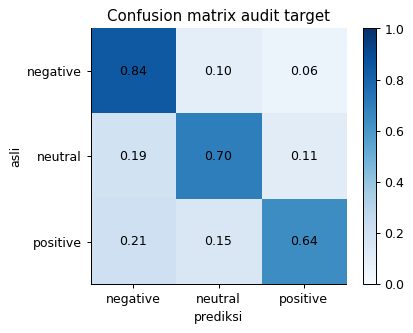

In [17]:
plot_confusion(y_target, final_probs.argmax(1), CLASSES, "Confusion matrix audit target")

## 11. Keluaran

File untuk dikumpulkan dan ringkasan run.

In [18]:
submission = pd.DataFrame(
    {"id": target.index, "label": [CLASSES[i] for i in final_probs.argmax(1)]}
)
submission.to_csv(RESULT_DIR / "submission.csv", index=False)
run_summary(
    "domain_shift",
    len(source) + len(target),
    {
        "auc_adversarial": round(shift_auc, 3),
        **{
            r["model"]: {"penjaga": r["penjaga_sumber"], "audit": r["audit_target"]}
            for r in results
        },
    },
    needs_gpu=USE_PRETRAINED,
)

RINGKASAN_RUN task=domain_shift mode=penuh n_rows=10000 total_detik=873 gpu=True
{
 "auc_adversarial": 0.992,
 "tfidf_sumber_saja": {
  "penjaga": 0.816,
  "audit": 0.5004
 },
 "teacher_sumber_saja": {
  "penjaga": 0.9517,
  "audit": 0.6799
 },
 "student_self_training": {
  "penjaga": 0.9502,
  "audit": 0.6424
 },
 "final": {
  "penjaga": 0.9517,
  "audit": 0.6799
 }
}


**Poin untuk presentasi**

ISI_SETELAH_EDA